In [ ]:
!pip -q install scikit-learn pandas numpy matplotlib seaborn gradio

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load dataset
cancer = load_breast_cancer(as_frame=True)

df_class = cancer.frame.copy()

# Separate features and target
X_class = df_class.drop(columns=["target"])
y_class = df_class["target"]

# Display dataset
print("Dataset shape:", df_class.shape)
print("\nFirst five records:")
display(df_class.head())

print("\nTarget classes:")
print(cancer.target_names)
print(y_class.value_counts().sort_index())

Dataset shape: (569, 31)

First five records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Target classes:
['malignant' 'benign']
target
0    212
1    357
Name: count, dtype: int64


In [ ]:
# Check data types
print("Data types:")
print(df_class.dtypes.value_counts())

# Missing values
print("\nMissing values:", df_class.isnull().sum().sum())

# Duplicate rows
print("Duplicate rows:", df_class.duplicated().sum())

# Remove duplicate rows if present
df_class = df_class.drop_duplicates().reset_index(drop=True)

# Separate features and target again
X_class = df_class.drop(columns=["target"])
y_class = df_class["target"]

print("\nDataset after cleaning:", df_class.shape)

Data types:
float64    30
int64       1
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0

Dataset after cleaning: (569, 31)


In [ ]:
display(X_class.describe().round(2))

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,...,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,...,16.27,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,...,4.83,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,...,7.93,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,...,13.01,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,...,14.97,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,...,18.79,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,...,36.04,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21


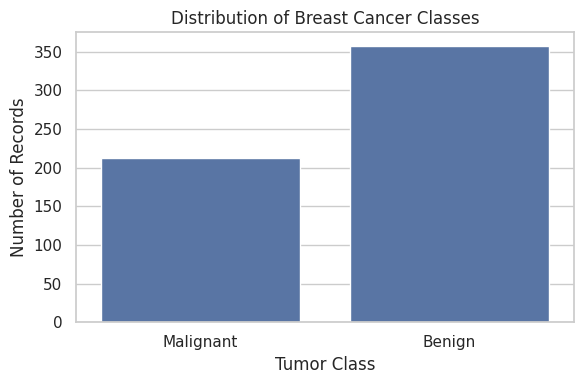

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(x=y_class.map({0: "Malignant", 1: "Benign"}))

plt.title("Distribution of Breast Cancer Classes")
plt.xlabel("Tumor Class")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

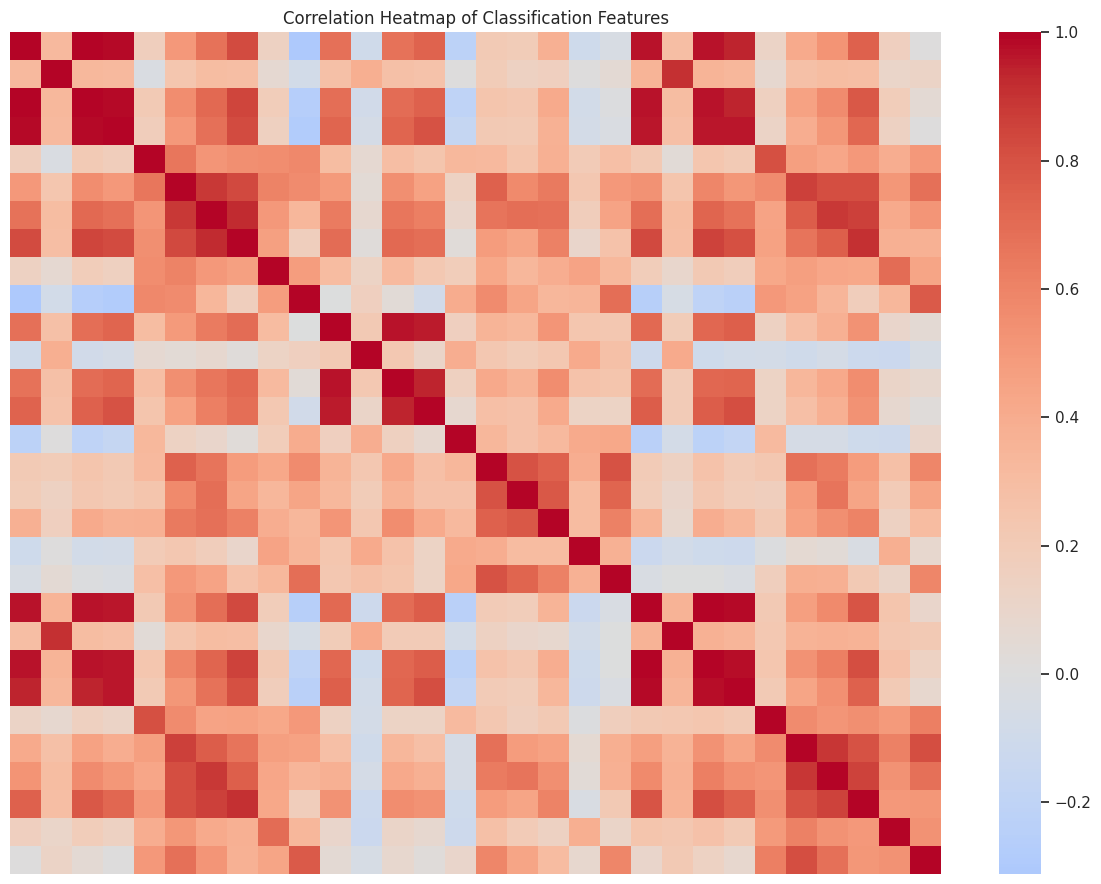

In [ ]:
plt.figure(figsize=(12, 9))

corr = X_class.corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Heatmap of Classification Features")
plt.tight_layout()
plt.show()

In [ ]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_class,
    y_class,
    test_size=0.20,
    random_state=42,
    stratify=y_class
)

print("Training records:", X_train_c.shape[0])
print("Testing records:", X_test_c.shape[0])

Training records: 455
Testing records: 114


In [ ]:
# Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_classifier.fit(X_train_c, y_train_c)

# Random Forest Classifier
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)

rf_classifier.fit(X_train_c, y_train_c)

print("Both classification models trained successfully!")

Both classification models trained successfully!


In [ ]:
# Generate predictions
y_pred_dt_c = dt_classifier.predict(X_test_c)
y_pred_rf_c = rf_classifier.predict(X_test_c)

# Evaluation function
def classification_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0)
    }

classification_results = pd.DataFrame([
    classification_metrics(
        y_test_c, y_pred_dt_c, "Decision Tree"
    ),
    classification_metrics(
        y_test_c, y_pred_rf_c, "Random Forest"
    )
])

display(classification_results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.9211,0.9565,0.9167,0.9362
1,Random Forest,0.9561,0.9589,0.9722,0.9655


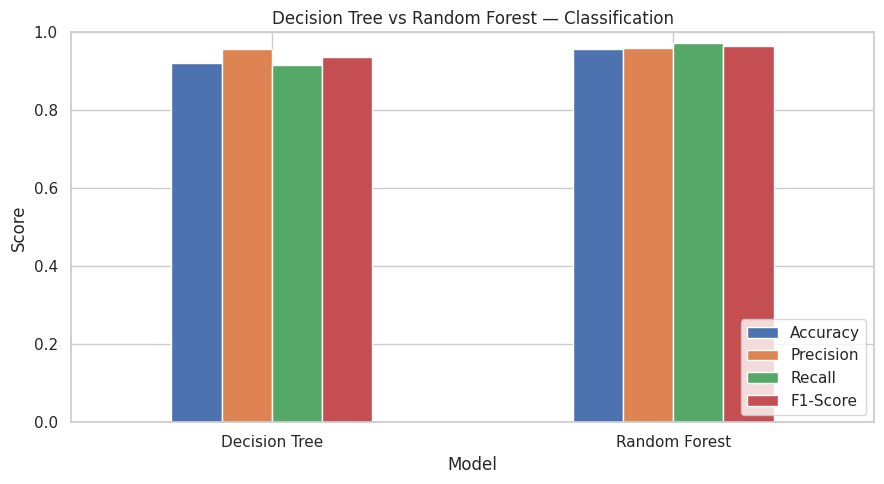

In [ ]:
classification_results.set_index("Model").plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Decision Tree vs Random Forest — Classification")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


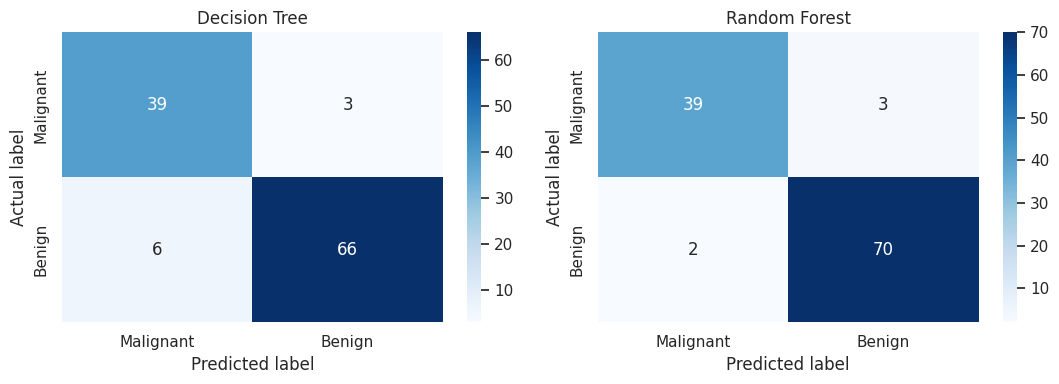

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, y_pred, name in [
    (axes[0], y_pred_dt_c, "Decision Tree"),
    (axes[1], y_pred_rf_c, "Random Forest")
]:
    cm = confusion_matrix(y_test_c, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Malignant", "Benign"],
        yticklabels=["Malignant", "Benign"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()

In [ ]:
# Load dataset
housing = fetch_california_housing(as_frame=True)

df_reg = housing.frame.copy()

# Separate features and target
X_reg = df_reg.drop(columns=["MedHouseVal"])
y_reg = df_reg["MedHouseVal"]

print("Dataset shape:", df_reg.shape)
print("\nFirst five records:")
display(df_reg.head())

print("\nTarget variable:", housing.target_names)

Dataset shape: (20640, 9)

First five records:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Target variable: ['MedHouseVal']


In [ ]:
print("Missing values:\n", df_reg.isnull().sum())
print("\nDuplicate rows:", df_reg.duplicated().sum())

# Remove duplicate rows if any
df_reg = df_reg.drop_duplicates().reset_index(drop=True)

# Separate features and target
X_reg = df_reg.drop(columns=["MedHouseVal"])
y_reg = df_reg["MedHouseVal"]

print("\nDataset after cleaning:", df_reg.shape)

Missing values:
 MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate rows: 0

Dataset after cleaning: (20640, 9)


In [ ]:
display(df_reg.describe().round(2))

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


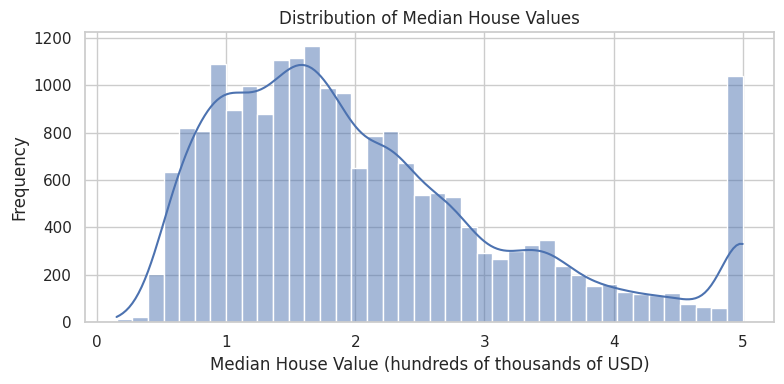

In [ ]:
plt.figure(figsize=(8, 4))

sns.histplot(y_reg, bins=40, kde=True)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (hundreds of thousands of USD)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

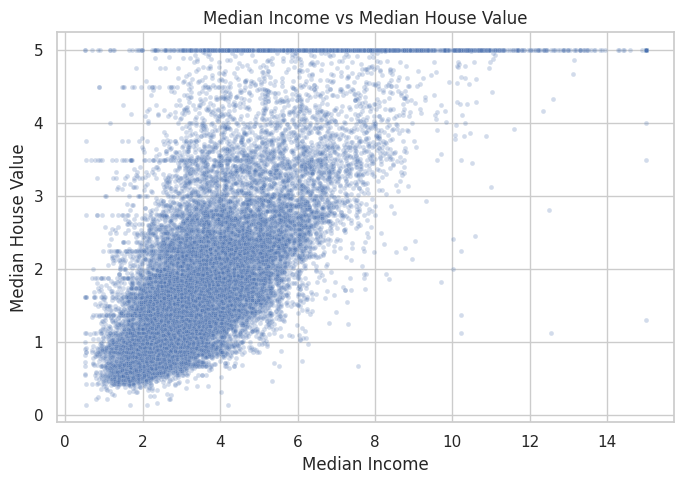

In [ ]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=X_reg["MedInc"],
    y=y_reg,
    alpha=0.25,
    s=12
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.tight_layout()
plt.show()

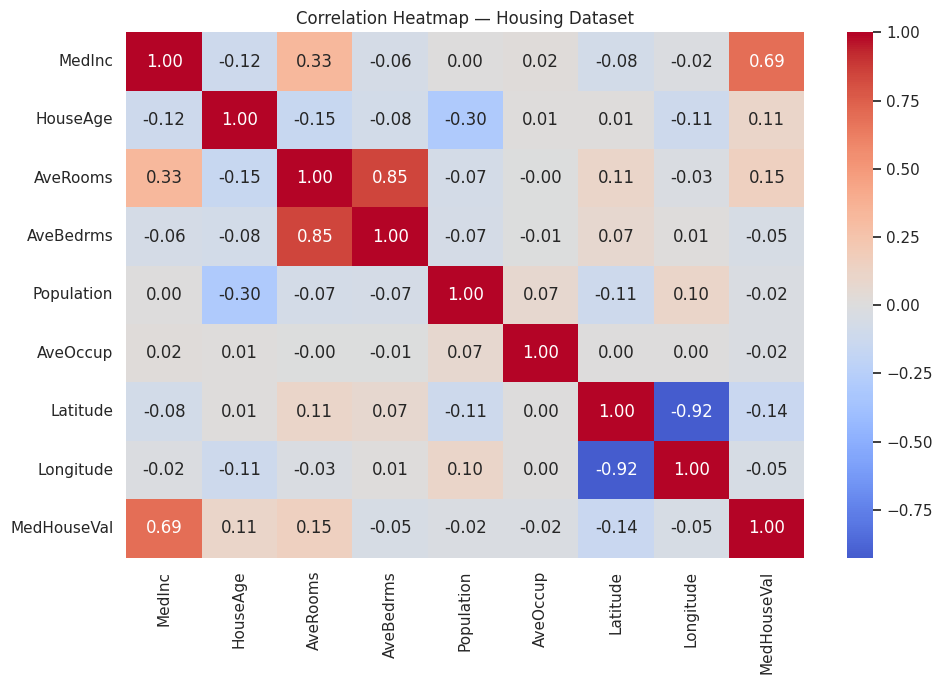

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df_reg.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap — Housing Dataset")
plt.tight_layout()
plt.show()

In [ ]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train_r.shape[0])
print("Testing records:", X_test_r.shape[0])

Training records: 16512
Testing records: 4128


In [ ]:
# Decision Tree Regressor
dt_regressor = DecisionTreeRegressor(
    max_depth=12,
    random_state=42
)

dt_regressor.fit(X_train_r, y_train_r)

# Random Forest Regressor
rf_regressor = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

rf_regressor.fit(X_train_r, y_train_r)

print("Both regression models trained successfully!")

Both regression models trained successfully!


In [ ]:
# Generate predictions
y_pred_dt_r = dt_regressor.predict(X_test_r)
y_pred_rf_r = rf_regressor.predict(X_test_r)

def regression_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2 Score": r2_score(y_true, y_pred)
    }

regression_results = pd.DataFrame([
    regression_metrics(
        y_test_r, y_pred_dt_r, "Decision Tree"
    ),
    regression_metrics(
        y_test_r, y_pred_rf_r, "Random Forest"
    )
])

display(regression_results.round(4))

,Model,MAE,RMSE,R2 Score
0,Decision Tree,0.4274,0.6591,0.6685
1,Random Forest,0.3459,0.5232,0.7911


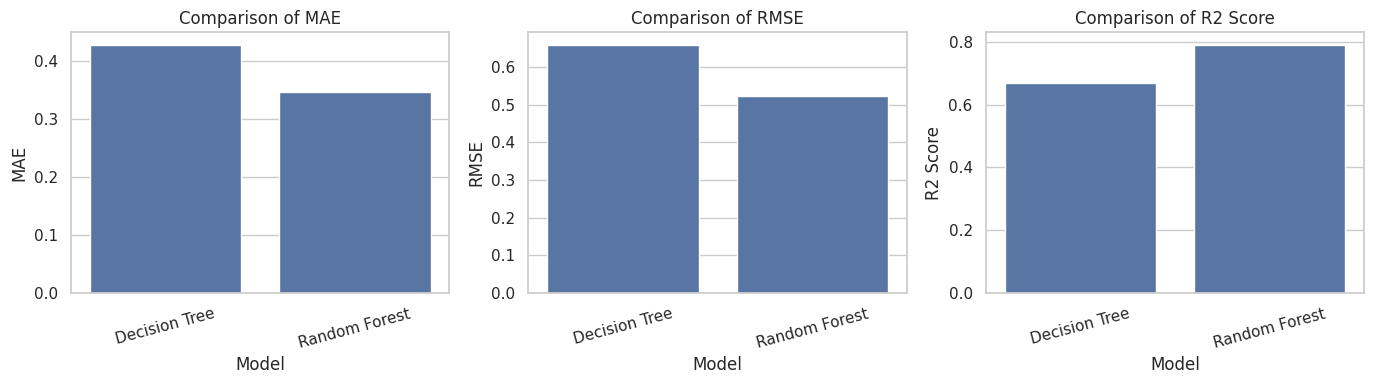

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

metrics = ["MAE", "RMSE", "R2 Score"]

for ax, metric in zip(axes, metrics):
    sns.barplot(
        data=regression_results,
        x="Model",
        y=metric,
        ax=ax
    )
    ax.set_title(f"Comparison of {metric}")
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

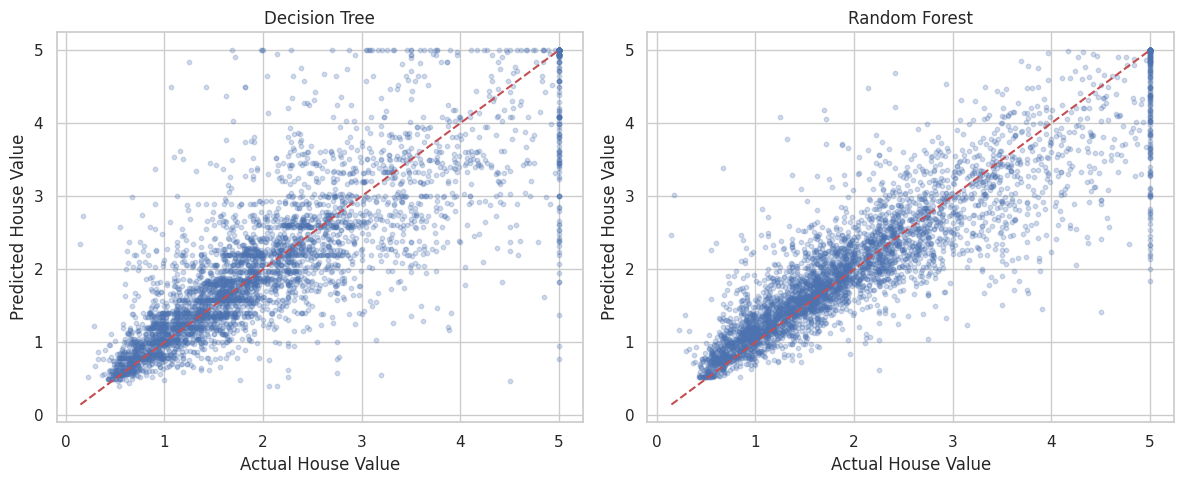

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, predictions, name in [
    (axes[0], y_pred_dt_r, "Decision Tree"),
    (axes[1], y_pred_rf_r, "Random Forest")
]:
    ax.scatter(y_test_r, predictions, alpha=0.25, s=10)

    lower = min(y_test_r.min(), predictions.min())
    upper = max(y_test_r.max(), predictions.max())

    ax.plot([lower, upper], [lower, upper], "r--")

    ax.set_title(name)
    ax.set_xlabel("Actual House Value")
    ax.set_ylabel("Predicted House Value")

plt.tight_layout()
plt.show()

In [ ]:
prediction_comparison = pd.DataFrame({
    "Actual Value": y_test_r.iloc[:10].values,
    "Decision Tree Prediction": y_pred_dt_r[:10],
    "Random Forest Prediction": y_pred_rf_r[:10]
})

display(prediction_comparison.round(3))

,Actual Value,Decision Tree Prediction,Random Forest Prediction
0,0.477,0.550,0.542
1,0.458,0.802,0.768
2,5.000,5.000,4.897
3,2.186,2.269,2.475
4,2.780,2.258,2.201
5,1.587,1.734,1.676
6,1.982,2.227,2.405
7,1.575,1.586,1.642
8,3.400,2.934,2.596
9,4.466,5.000,4.915


,Importance
worst area,0.138294
worst concave points,0.132993
worst radius,0.100805
mean concave points,0.098489
worst perimeter,0.072224
mean perimeter,0.068612
mean radius,0.067465
mean concavity,0.057445
mean area,0.050615
worst concavity,0.031544


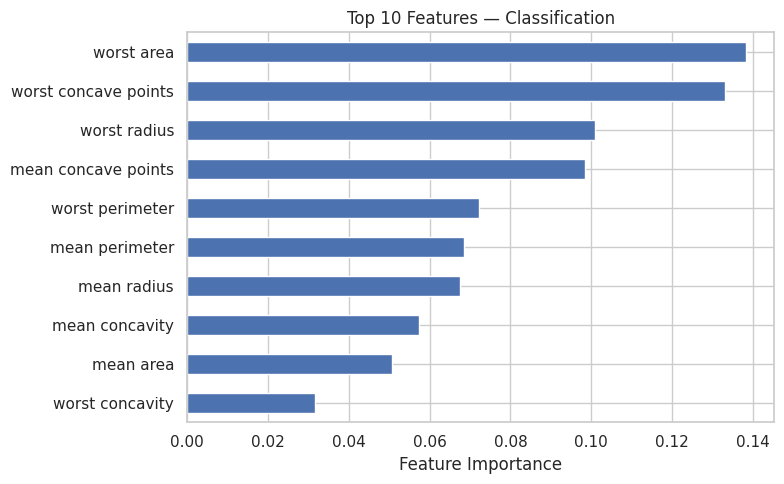

In [ ]:
class_importance = pd.Series(
    rf_classifier.feature_importances_,
    index=X_train_c.columns
).sort_values(ascending=False)

display(class_importance.head(10).to_frame("Importance"))

class_importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Top 10 Features — Classification")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

,Importance
MedInc,0.560724
AveOccup,0.139083
Latitude,0.083760
Longitude,0.083498
HouseAge,0.050388
AveRooms,0.037246
Population,0.022905
AveBedrms,0.022395


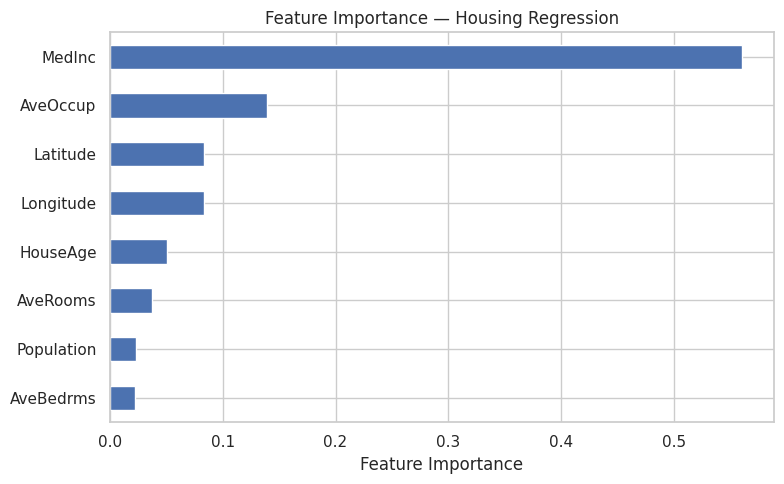

In [ ]:
reg_importance = pd.Series(
    rf_regressor.feature_importances_,
    index=X_train_r.columns
).sort_values(ascending=False)

display(reg_importance.to_frame("Importance"))

reg_importance.sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Feature Importance — Housing Regression")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [ ]:
import gradio as gr

# ---------- CLASSIFICATION INTERFACE ----------

def predict_tumor(sample_number):
    idx = int(sample_number)

    sample = X_test_c.iloc[[idx]]
    prediction = int(rf_classifier.predict(sample)[0])
    probabilities = rf_classifier.predict_proba(sample)[0]

    label = cancer.target_names[prediction]

    return (
        f"Predicted class: {label}",
        {
            "malignant": float(probabilities[0]),
            "benign": float(probabilities[1])
        }
    )


# ---------- REGRESSION INTERFACE ----------

def predict_house(
    MedInc, HouseAge, AveRooms, AveBedrms,
    Population, AveOccup, Latitude, Longitude
):
    sample = pd.DataFrame([{
        "MedInc": MedInc,
        "HouseAge": HouseAge,
        "AveRooms": AveRooms,
        "AveBedrms": AveBedrms,
        "Population": Population,
        "AveOccup": AveOccup,
        "Latitude": Latitude,
        "Longitude": Longitude
    }])

    prediction = rf_regressor.predict(sample)[0]
    predicted_usd = prediction * 100000

    return (
        f"Predicted median house value: "
        f"${predicted_usd:,.0f}"
    )


# ---------- CREATE APPLICATION ----------

with gr.Blocks() as demo:
    gr.Markdown("# Decision Tree and Random Forest Prediction App")

    with gr.Tab("Classification — Breast Cancer"):
        gr.Markdown(
            "Select a held-out test sample to demonstrate "
            "the Random Forest classifier."
        )

        sample_number = gr.Dropdown(
            choices=[str(i) for i in range(len(X_test_c))],
            value="0",
            label="Test sample number"
        )

        tumor_button = gr.Button("Predict Tumor Class")
        tumor_output = gr.Textbox(label="Prediction")
        probability_output = gr.Label(label="Model probabilities")

        tumor_button.click(
            predict_tumor,
            inputs=sample_number,
            outputs=[tumor_output, probability_output]
        )

    with gr.Tab("Regression — California Housing"):
        gr.Markdown(
            "Enter housing features to predict median house value. "
            "Use plausible values within the dataset's feature ranges."
        )

        inputs = [
            gr.Number(label="Median Income (MedInc)", value=3.5),
            gr.Number(label="House Age (HouseAge)", value=25),
            gr.Number(label="Average Rooms (AveRooms)", value=5.0),
            gr.Number(label="Average Bedrooms (AveBedrms)", value=1.0),
            gr.Number(label="Population", value=1000),
            gr.Number(label="Average Occupancy (AveOccup)", value=3.0),
            gr.Number(label="Latitude", value=34.0),
            gr.Number(label="Longitude", value=-118.0)
        ]

        house_button = gr.Button("Predict House Value")
        house_output = gr.Textbox(label="Prediction")

        house_button.click(
            predict_house,
            inputs=inputs,
            outputs=house_output
        )

demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [ ]:
# Save evaluation tables
classification_results.to_csv(
    "classification_results.csv", index=False
)

regression_results.to_csv(
    "regression_results.csv", index=False
)

# Save feature importance tables
class_importance.rename("Importance").to_csv(
    "classification_feature_importance.csv"
)

reg_importance.rename("Importance").to_csv(
    "regression_feature_importance.csv"
)

# Save the cleaned datasets
df_class.to_csv("breast_cancer_cleaned.csv", index=False)
df_reg.to_csv("california_housing_cleaned.csv", index=False)

print("All result files saved successfully!")

All result files saved successfully!
